# 04 · Catálogo regional desde el DENUE (INEGI)

**Fuente:** Directorio Estadístico Nacional de Unidades Económicas, descarga masiva de Veracruz (entidad 30).
**Región:** los 57 municipios de las Altas Montañas.
**Salida:** `data/catalogo/catalogo_denue_altas_montanas.csv` y el bloque idempotente del catálogo dentro de `API/bd.sql`.

| Paso | Regla |
|---|---|
| Extraer | CSV del zip del DENUE (se lee directo del zip) |
| Filtrar región | municipio normalizado (sin acentos) dentro de la lista de 57 |
| Seleccionar | actividades SCIAN de hospedaje, restaurantes establecidos, cafeterías, museos, sitios naturales, balnearios, excursiones y artesanías; además palabras clave del nombre (temazcal, spa, yoga, cabañas, ecoturismo…) **solo dentro de actividades de servicio afines** |
| Excluir | moteles, autolavados, estéticas caninas, consultorios; sin coordenadas o fuera de la región |
| Duplicados | mismo nombre a menos de ~100 m |
| MiPyME | estrato oficial de personal ocupado ≤ 100 personas |
| Etiquetar | modalidades W1–W7 propuestas por regla, con evidencia textual (actividad SCIAN) y nota de verificación en campo |

In [1]:
import sys, os, json
from pathlib import Path
SRC = next(p for p in [Path('src'), Path('../src'), Path('MODELO/src')] if (p / 'encuesta_etl.py').exists()).resolve()
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lab_graficas import aplicar_estilo, guardar, SERIES, TEXTO_2, ETIQUETAS_W
aplicar_estilo()
pd.set_option('display.max_columns', 30)

In [2]:
from denue_etl import ejecutar, SALIDA
carpeta = Path(os.environ.get('DENUE_DIR', r'C:/Users/Hp Martin/Documents/MTY-Welltur/DENUE_DescargaMasiva4112026_1170'))
import re

def edicion(p):
    # denue_30_csv.zip es la edición vigente; las históricas usan MMAA (0525) o DDMMAAAA (25022015).
    m = re.search(r'denue_30_(\d+)_csv', p.name)
    if not m:
        return (9999, 99)
    s = m.group(1)
    return (int(s[-4:]), int(s[2:4])) if len(s) == 8 else (2000 + int(s[2:]), int(s[:2])) if len(s) == 4 else (int(s), 0)

zips = sorted(carpeta.glob('*denue_30*_csv.zip'), key=edicion)
print('Edición usada:', zips[-1].name if zips else '(catálogo previo)')
if zips:
    ejecutar(zips[-1])  # si no hay zip local se usa el último catálogo generado
catalogo = pd.read_csv(SALIDA)
bitacora = json.loads(SALIDA.with_suffix('.log.json').read_text(encoding='utf-8'))
{k: v for k, v in bitacora.items() if not isinstance(v, dict)}

Edición usada: 49_denue_30_csv.zip


{'edicion_denue': '0526',
 'registros_entidad': 356724,
 'registros_region': 69995,
 'municipios_sin_registros': [],
 'excluidos_sin_coordenadas_validas': 0,
 'excluidos_duplicados': 3,
 'catalogo_final': 1121,
 'mipyme_pct': 100.0,
 'municipios_con_oferta': 48,
 'fuente': '49_denue_30_csv.zip'}

In [3]:
resumen = (catalogo.groupby('categoria_wellness')
             .agg(lugares=('nombre', 'size'), mipyme_pct=('es_mipyme', lambda s: round(s.mean() * 100, 1)),
                  municipios=('municipio', 'nunique'))
             .sort_values('lugares', ascending=False))
resumen

,lugares,mipyme_pct,municipios
categoria_wellness,,,
Gastronomia,591,100.0,39
Hospedaje,196,100.0,29
Artesania,143,100.0,30
Spa_Temazcal,71,100.0,18
Balneario,60,100.0,25
Cultura,29,100.0,9
Mente_Cuerpo,13,100.0,6
Naturaleza,7,100.0,4
Hospedaje_Naturaleza,4,100.0,3


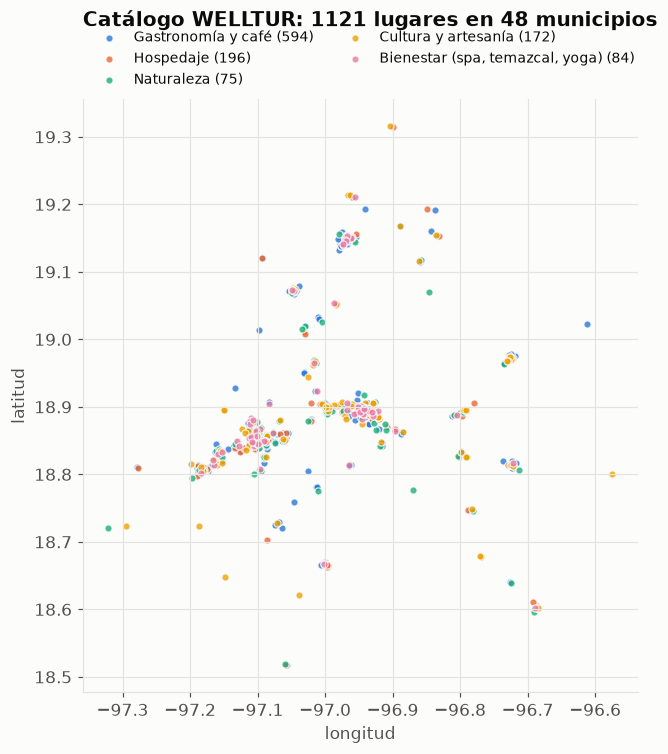

In [4]:
GRUPOS = {'Gastronomia': 'Gastronomía y café', 'Cafe_de_Altura': 'Gastronomía y café', 'Hospedaje': 'Hospedaje',
          'Hospedaje_Naturaleza': 'Naturaleza', 'Naturaleza': 'Naturaleza', 'Naturaleza_Aventura': 'Naturaleza',
          'Balneario': 'Naturaleza', 'Cultura': 'Cultura y artesanía', 'Artesania': 'Cultura y artesanía',
          'Spa_Temazcal': 'Bienestar (spa, temazcal, yoga)', 'Mente_Cuerpo': 'Bienestar (spa, temazcal, yoga)'}
catalogo['grupo'] = catalogo['categoria_wellness'].map(GRUPOS)
orden = ['Gastronomía y café', 'Hospedaje', 'Naturaleza', 'Cultura y artesanía', 'Bienestar (spa, temazcal, yoga)']
fig, ax = plt.subplots(figsize=(7.5, 7))
for color, grupo in zip(SERIES, orden):
    d = catalogo[catalogo['grupo'] == grupo]
    ax.scatter(d['longitud'], d['latitud'], s=22, color=color, alpha=0.8, edgecolor='#fcfcfb', linewidth=0.8,
               label=f'{grupo} ({len(d)})')
ax.set_aspect('equal'); ax.set_xlabel('longitud'); ax.set_ylabel('latitud')
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0), ncols=2, fontsize=9)
ax.set_title(f'Catálogo WELLTUR: {len(catalogo)} lugares en {catalogo.municipio.nunique()} municipios', pad=48)
guardar(fig, '04_mapa_catalogo');

## Cobertura por modalidad W1–W7 y por municipio

,lugares
W1,745
W2,75
W3,7
W4,13
W5,594
W6,179
W7,309


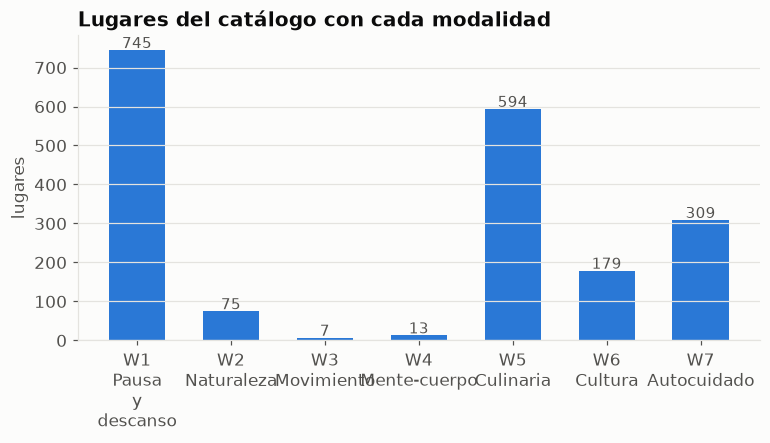

In [5]:
mods = catalogo['wellness_modalities'].map(lambda s: json.loads(s.replace("'", '"')))
cobertura = pd.Series([w for m in mods for w in m]).value_counts().reindex(ETIQUETAS_W.keys(), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar([ETIQUETAS_W[w].replace(' ', '\n') for w in cobertura.index], cobertura.values, color=SERIES[0], width=0.6)
for i, v in enumerate(cobertura.values):
    ax.text(i, v + 5, str(v), ha='center', color=TEXTO_2, fontsize=10)
ax.set_ylabel('lugares'); ax.grid(axis='x', visible=False)
ax.set_title('Lugares del catálogo con cada modalidad')
guardar(fig, '04_cobertura_w');
cobertura.to_frame('lugares')

In [6]:
catalogo.groupby('municipio').agg(lugares=('nombre', 'size'), mipyme=('es_mipyme', 'sum')).sort_values('lugares', ascending=False).head(15)

,lugares,mipyme
municipio,,
Orizaba,354,354
Córdoba,289,289
Huatusco,67,67
Fortín,52,52
Camerino Z. Mendoza,40,40
Coscomatepec,32,32
Ixtaczoquitlán,26,26
Nogales,25,25
Río Blanco,24,24


## Límites
* Las etiquetas W son una **propuesta por reglas** (actividad SCIAN + nombre); cada lugar queda anotado como pendiente de verificación en campo. Las 6 experiencias del recorrido de campo del equipo sí están verificadas.
* El DENUE registra unidades económicas: no incluye atractivos naturales sin un negocio (cascadas o miradores públicos), que se agregan a mano en PLATAFORMA.
* Los municipios con menos establecimientos turísticos quedan con poca o ninguna oferta en el catálogo.